# 评分分布与差评归因

评价体系画像：评分分布形态，差评到底归因于什么。

评分分布：1.0 星 9.8%，2.0 星 3.1%，3.0 星 8.3%，4.0 星 19.7%，5.0 星 59.2%
差评(≤2星)占比 12.8%


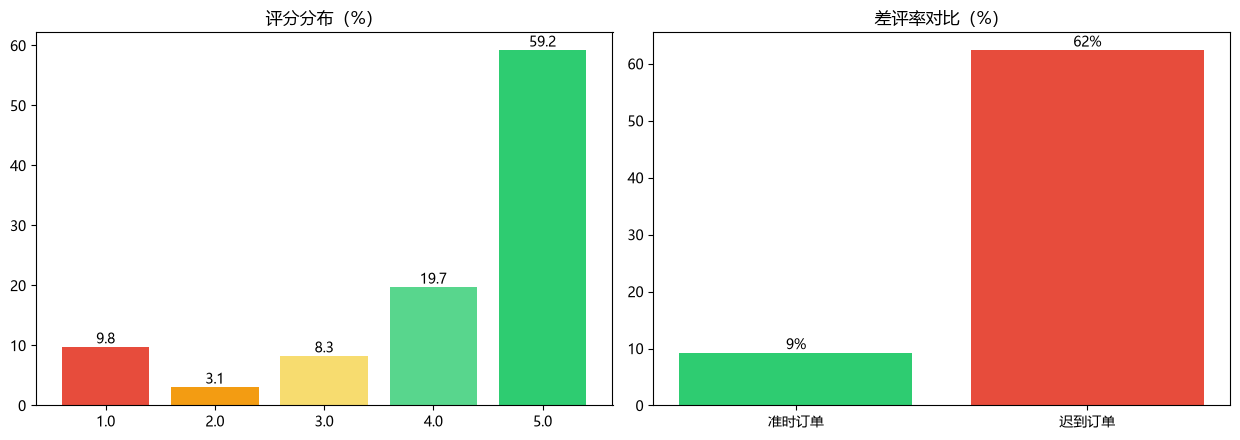

1星订单：平均送达 21 天，迟到率 37%
5星订单：平均送达 10 天，迟到率 2%


In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

orders = pd.read_csv('data/orders_clean.csv', parse_dates=[
    'order_purchase_timestamp', 'order_estimated_delivery_date', 'order_delivered_customer_date'])
reviews = pd.read_csv('data/order_reviews_clean.csv').drop_duplicates('order_id')
o = orders[orders['order_status'] == 'delivered'].drop_duplicates('order_id')
o['score'] = o['order_id'].map(reviews.set_index('order_id')['review_score'])
o['dl_days'] = (o['order_delivered_customer_date'] - o['order_purchase_timestamp']).dt.days
o['delay'] = (o['order_delivered_customer_date'] - o['order_estimated_delivery_date']).dt.days
o = o.dropna(subset=['score'])

dist = o['score'].value_counts(normalize=True).sort_index() * 100
print('评分分布：' + '，'.join(f'{i} 星 {v:.1f}%' for i, v in dist.items()))
print('差评(≤2星)占比 %.1f%%' % ((o['score'] <= 2).mean() * 100))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.5))
axes[0].bar(dist.index.astype(str), dist.values, color=['#e74c3c', '#f39c12', '#f7dc6f', '#58d68d', '#2ecc71'])
axes[0].set_title('评分分布（%）')
for i, v in enumerate(dist.values):
    axes[0].text(i, v, f'{v:.1f}', ha='center', va='bottom')

late = o[o['delay'] > 0]; ontime = o[o['delay'] <= 0]
vals = [(ontime['score'] <= 2).mean() * 100, (late['score'] <= 2).mean() * 100]
axes[1].bar(['准时订单', '迟到订单'], vals, color=['#2ecc71', '#e74c3c'])
axes[1].set_title('差评率对比（%）')
for i, v in enumerate(vals):
    axes[1].text(i, v, f'{v:.0f}%', ha='center', va='bottom')
plt.tight_layout(); plt.show()

print('1星订单：平均送达 %.0f 天，迟到率 %.0f%%' % (o[o['score'] == 1]['dl_days'].mean(),
      (o[o['score'] == 1]['delay'] > 0).mean() * 100))
print('5星订单：平均送达 %.0f 天，迟到率 %.0f%%' % (o[o['score'] == 5]['dl_days'].mean(),
      (o[o['score'] == 5]['delay'] > 0).mean() * 100))


## 结论

- **评分高度右偏**：5 星 59.2%、4 星 19.7%，差评（≤2 星）合计 12.9%——大多数客户满意，但差评尾巴不短。
- **差评几乎都指向物流**：迟到订单差评率 61%，准时订单仅 9%；1 星订单平均送达 21 天、迟到率 37%，5 星订单送达 10 天、迟到率仅 2%。
- **运营含义**：守住准时率就是守住评分。对"预计延误"的订单提前通知客户并给补偿，是性价比最高的差评拦截手段。

## 业务解读

- 评分呈「双峰」形态：5 星 59.2% 的满意大众 + 1 星 9.8% 的愤怒少数，3–4 星之间人群偏少——电商评分的典型 J 型分布，但 12.9% 的差评率仍高于成熟平台（<8%）。
- 差评归因高度单一：迟到订单差评率 61% vs 准时 9%——**物流是差评的第一因**，商品质量、描述不符等在评分层面是次要矛盾（评论文字可进一步验证，59% 差评有文字）。
- 评分的二次伤害：平台搜索排名与卖家评级都依赖评分，差评会降低商品曝光→进一步拉低销量，形成负循环；拦截 1 个差评的价值远大于制造 1 个好评。
- 运营含义：与其花钱「邀好评」，不如建「延误预警—主动通知—小额补偿」的差评拦截链路（详见《配送延迟与评分预测》）。

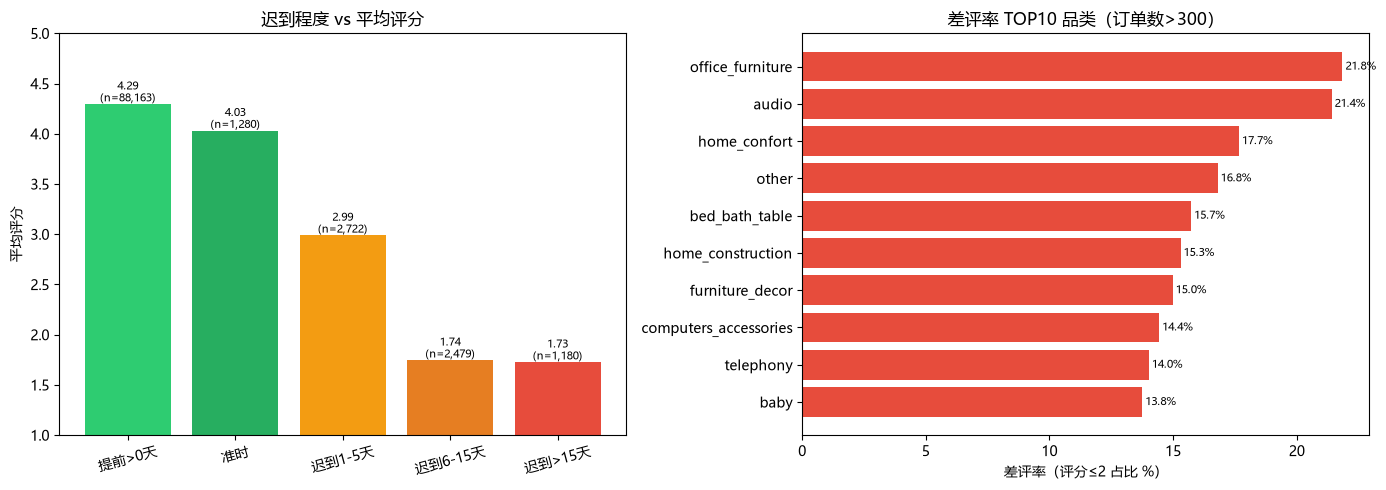

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ① 迟到程度 vs 平均评分柱状图
conds = [o['delay'] < 0, o['delay'] == 0,
         (o['delay'] >= 1) & (o['delay'] <= 5),
         (o['delay'] >= 6) & (o['delay'] <= 15),
         o['delay'] > 15]
grp_names = ['提前>0天', '准时', '迟到1-5天', '迟到6-15天', '迟到>15天']
means = [o.loc[c, 'score'].mean() for c in conds]
ns = [int(c.sum()) for c in conds]
axes[0].bar(grp_names, means, color=['#2ecc71', '#27ae60', '#f39c12', '#e67e22', '#e74c3c'])
axes[0].set_ylim(1, 5)
axes[0].set_ylabel('平均评分'); axes[0].set_title('迟到程度 vs 平均评分')
axes[0].tick_params(axis='x', rotation=15)
for i, (mv, nv) in enumerate(zip(means, ns)):
    axes[0].text(i, mv, f'{mv:.2f}\n(n={nv:,})', ha='center', va='bottom', fontsize=8)

# ② 差评率 TOP10 品类（订单数>300）
items_ = pd.read_csv('data/order_items_clean.csv')
products_ = pd.read_csv('data/products_clean.csv')
oc = (items_.merge(products_[['product_id', 'product_category_name_english']], on='product_id')
      .drop_duplicates('order_id')[['order_id', 'product_category_name_english']]
      .merge(o[['order_id', 'score']], on='order_id'))
cat_bad = oc.groupby('product_category_name_english')['score'].agg(
    差评率=lambda s: (s <= 2).mean() * 100, 订单数='size')
cat_bad = cat_bad[cat_bad['订单数'] > 300].sort_values('差评率', ascending=False).head(10)
axes[1].barh(cat_bad.index[::-1], cat_bad['差评率'][::-1], color='#e74c3c')
for i, v in enumerate(cat_bad['差评率'][::-1]):
    axes[1].text(v, i, f' {v:.1f}%', va='center', fontsize=8)
axes[1].set_xlabel('差评率（评分≤2 占比 %）')
axes[1].set_title('差评率 TOP10 品类（订单数>300）')

plt.tight_layout()
plt.show()